# Rod Identifier — Canny Edge Method
Detects and crops individual rods from a photo using Canny edge detection + column/row projection.

**Pipeline:**
1. Grayscale → Gaussian blur
2. Canny edge detection
3. **Column** projection → find rod x-bands (left/right)
4. Per-rod **row** projection → find each rod's individual top/bottom
5. Crop each rod and export

In [226]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

## Parameters

In [227]:
# ── Input / Output ────────────────────────────────────────────────────────────
IMAGE_PATH = "ekseperiment_efter_omroering.jpg"
OUTPUT_DIR = "rod_crops"

# ── Canny edge detection ──────────────────────────────────────────────────────
BLUR_KERNEL    = (5, 5)
CANNY_LOW      = 30
CANNY_HIGH     = 90

# ── Column projection → left/right band detection ────────────────────────────
COL_SMOOTH_WIN  = 7
COL_SIGNAL_RATIO= 0.15
COL_BORDER      = 20
COL_BAND_GAP    = 10
MIN_BAND_W      = 8
MAX_BAND_W      = 60

# ── Per-rod row projection → top/bottom detection ────────────────────────────
ROW_SMOOTH_WIN  = 15      # moving-average window for row projection
ROW_SIGNAL_RATIO= 0.15    # threshold = median + ratio × (peak − median)
ROW_BORDER      = 10      # pixels ignored at top/bottom edges

# ── Crop padding ─────────────────────────────────────────────────────────────
CROP_PAD_X     = 10
CROP_PAD_Y     = 1

## Step 1 — Load image

Loaded: ekseperiment_efter_omroering.jpg  (2048 × 1536 px)


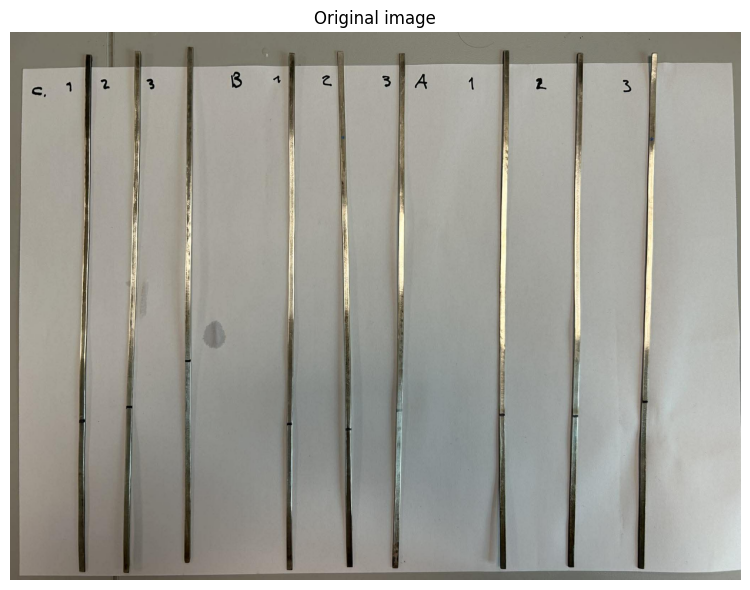

In [228]:
img_bgr = cv2.imread(IMAGE_PATH)
assert img_bgr is not None, f"Could not load image: {IMAGE_PATH}"

img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
H, W    = img_bgr.shape[:2]
print(f"Loaded: {IMAGE_PATH}  ({W} × {H} px)")

plt.figure(figsize=(12, 6))
plt.imshow(img_rgb)
plt.title("Original image")
plt.axis("off")
plt.tight_layout()
plt.show()

## Step 2 — Grayscale → Gaussian Blur → Canny edges

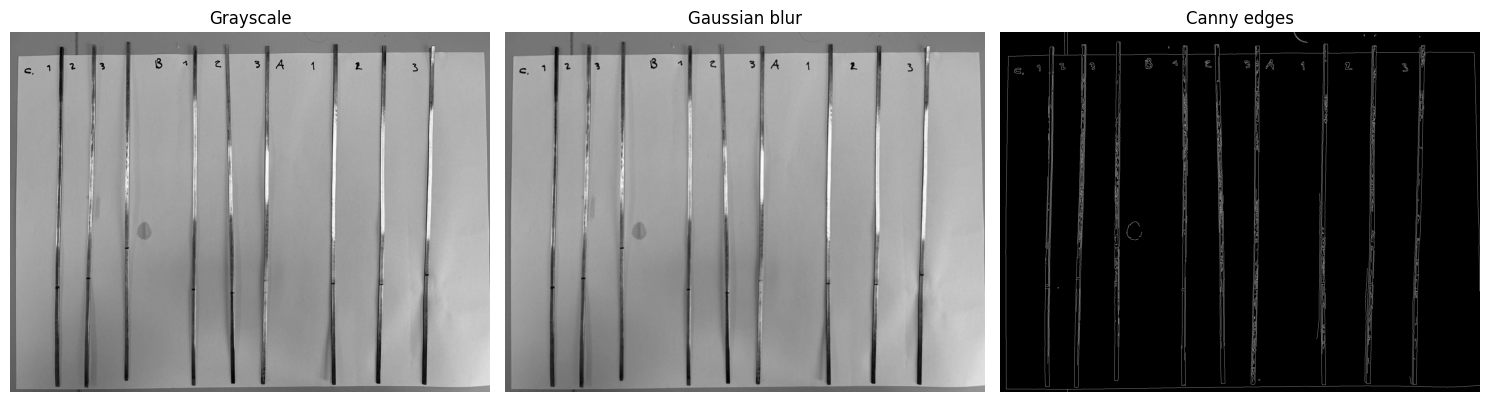

In [229]:
gray    = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, BLUR_KERNEL, 0)
edges   = cv2.Canny(blurred, CANNY_LOW, CANNY_HIGH)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, data, title in zip(axes,
                           [gray, blurred, edges],
                           ["Grayscale", "Gaussian blur", "Canny edges"]):
    ax.imshow(data, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Step 3 — Column projection → rod x-bands

Detected 10 rod band(s):
  Rod 01: x = 22 → 32  (width = 10 px)
  Rod 02: x = 190 → 229  (width = 39 px)
  Rod 03: x = 320 → 366  (width = 46 px)
  Rod 04: x = 487 → 514  (width = 27 px)
  Rod 05: x = 774 → 801  (width = 27 px)
  Rod 06: x = 923 → 959  (width = 36 px)
  Rod 07: x = 1074 → 1108  (width = 34 px)
  Rod 08: x = 1361 → 1396  (width = 35 px)
  Rod 09: x = 1559 → 1601  (width = 42 px)
  Rod 10: x = 1760 → 1807  (width = 47 px)


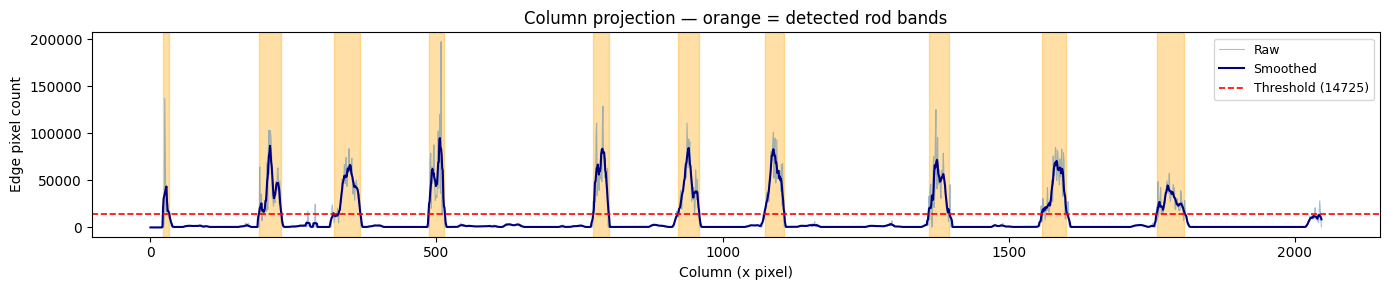

In [230]:
col_proj   = edges.sum(axis=0).astype(float)
col_smooth = np.convolve(col_proj, np.ones(COL_SMOOTH_WIN)/COL_SMOOTH_WIN, mode="same")
col_thr    = np.median(col_smooth) + COL_SIGNAL_RATIO * (col_smooth.max() - np.median(col_smooth))

active_cols = np.where(col_smooth > col_thr)[0]
active_cols = active_cols[(active_cols >= COL_BORDER) & (active_cols < W - COL_BORDER)]

groups = np.split(active_cols, np.where(np.diff(active_cols) > COL_BAND_GAP)[0] + 1) if len(active_cols) else []
bands  = [(int(g[0]), int(g[-1])) for g in groups if MIN_BAND_W <= len(g) <= MAX_BAND_W]

print(f"Detected {len(bands)} rod band(s):")
for i, (x0, x1) in enumerate(bands, 1):
    print(f"  Rod {i:02d}: x = {x0} → {x1}  (width = {x1-x0} px)")

fig, ax = plt.subplots(figsize=(14, 3))
ax.plot(col_proj,   color="steelblue", lw=0.8, alpha=0.5, label="Raw")
ax.plot(col_smooth, color="navy",      lw=1.5,             label="Smoothed")
ax.axhline(col_thr, color="red", ls="--", lw=1.2, label=f"Threshold ({col_thr:.0f})")
for x0, x1 in bands:
    ax.axvspan(x0, x1, color="orange", alpha=0.35)
ax.set_xlabel("Column (x pixel)")
ax.set_ylabel("Edge pixel count")
ax.set_title("Column projection — orange = detected rod bands")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## Step 4 — Per-rod row projection → individual top / bottom
For each x-band, slice out that rod's columns from the edge image and run the row projection only on that strip. This lets each rod have its own vertical crop.

In [231]:
def find_row_extent(edge_strip, full_H):
    """Run row projection on a vertical strip and return (top, bottom) pixel rows."""
    row_proj   = edge_strip.sum(axis=1).astype(float)
    row_smooth = np.convolve(row_proj, np.ones(ROW_SMOOTH_WIN)/ROW_SMOOTH_WIN, mode="same")
    row_thr    = np.median(row_smooth) + ROW_SIGNAL_RATIO * (row_smooth.max() - np.median(row_smooth))
    active     = np.where(row_smooth > row_thr)[0]
    active     = active[(active >= ROW_BORDER) & (active < full_H - ROW_BORDER)]
    if len(active) == 0:
        return ROW_BORDER, full_H - ROW_BORDER   # fallback: full height
    return int(active[0]), int(active[-1])


# Compute per-rod y extents
rod_extents = []   # list of (x0, x1, y_top, y_bot) per rod

for i, (x0, x1) in enumerate(bands, 1):
    px0 = max(0, x0 - CROP_PAD_X)
    px1 = min(W, x1 + CROP_PAD_X)
    strip     = edges[:, px0:px1]
    top, bot  = find_row_extent(strip, H)
    y0 = max(0, top - CROP_PAD_Y)
    y1 = min(H, bot + CROP_PAD_Y)
    rod_extents.append((px0, px1, y0, y1))
    print(f"  Rod {i:02d}: x = {px0}→{px1}  |  y = {y0}→{y1}  ({px1-px0} × {y1-y0} px)")

  Rod 01: x = 12→42  |  y = 107→1526  (30 × 1419 px)
  Rod 02: x = 180→239  |  y = 69→1521  (59 × 1452 px)
  Rod 03: x = 310→376  |  y = 58→1522  (66 × 1464 px)
  Rod 04: x = 477→524  |  y = 89→1238  (47 × 1149 px)
  Rod 05: x = 764→811  |  y = 61→1513  (47 × 1452 px)
  Rod 06: x = 913→969  |  y = 57→1108  (56 × 1051 px)
  Rod 07: x = 1064→1118  |  y = 84→1480  (54 × 1396 px)
  Rod 08: x = 1351→1406  |  y = 56→1512  (55 × 1456 px)
  Rod 09: x = 1549→1611  |  y = 80→1505  (62 × 1425 px)
  Rod 10: x = 1750→1817  |  y = 60→1519  (67 × 1459 px)


## Step 5 — Overlay per-rod bounding boxes on image

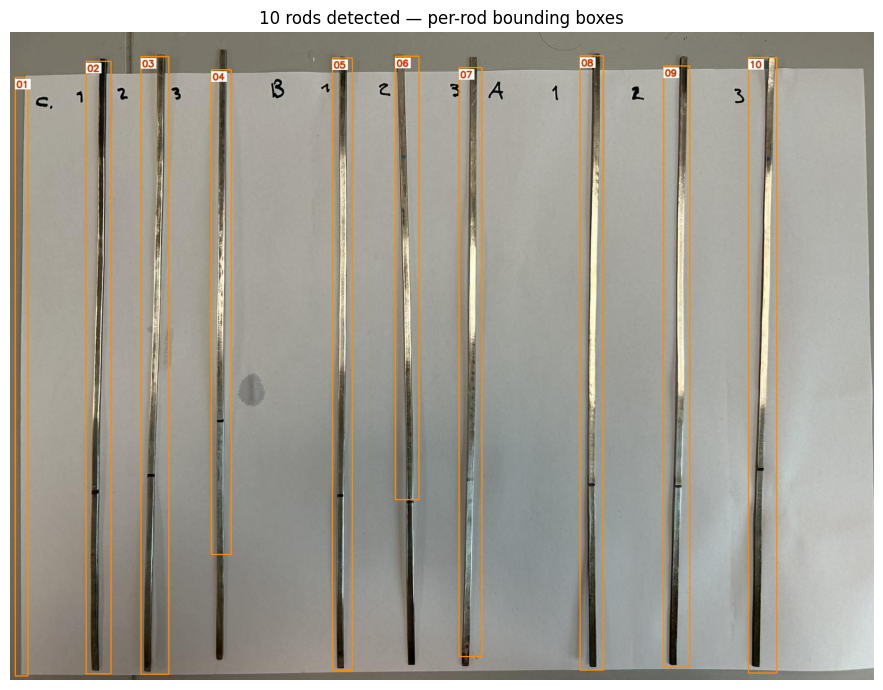

In [232]:
annotated = img_rgb.copy()

for i, (px0, px1, y0, y1) in enumerate(rod_extents, 1):
    cv2.rectangle(annotated, (px0, y0), (px1, y1), (255, 140, 0), 2)
    label = f"{i:02d}"
    (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.7, 2)
    cv2.rectangle(annotated, (px0, y0 + 4), (px0 + tw + 6, y0 + th + 12), (255,255,255), cv2.FILLED)
    cv2.putText(annotated, label, (px0 + 3, y0 + th + 8),
                cv2.FONT_HERSHEY_SIMPLEX, 0.7, (200, 60, 0), 2, cv2.LINE_AA)

plt.figure(figsize=(14, 7))
plt.imshow(annotated)
plt.title(f"{len(rod_extents)} rods detected — per-rod bounding boxes")
plt.axis("off")
plt.tight_layout()
plt.show()

## Step 6 — Crop and export each rod

In [233]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

saved_paths = []
crops       = []
stem = os.path.splitext(os.path.basename(IMAGE_PATH))[0]

for i, (px0, px1, y0, y1) in enumerate(rod_extents, 1):
    crop_bgr = img_bgr[y0:y1, px0:px1]
    crop_rgb = img_rgb[y0:y1, px0:px1]

    out_path = os.path.join(OUTPUT_DIR, f"{stem}_rod_{i:02d}.png")
    cv2.imwrite(out_path, crop_bgr)
    saved_paths.append(out_path)
    crops.append(crop_rgb)
    print(f"  Rod {i:02d} → {out_path}  ({px1-px0} × {y1-y0} px)")

print(f"\n✓ {len(saved_paths)} crops saved to '{OUTPUT_DIR}/'")

  Rod 01 → rod_crops\ekseperiment_efter_omroering_rod_01.png  (30 × 1419 px)
  Rod 02 → rod_crops\ekseperiment_efter_omroering_rod_02.png  (59 × 1452 px)
  Rod 03 → rod_crops\ekseperiment_efter_omroering_rod_03.png  (66 × 1464 px)
  Rod 04 → rod_crops\ekseperiment_efter_omroering_rod_04.png  (47 × 1149 px)
  Rod 05 → rod_crops\ekseperiment_efter_omroering_rod_05.png  (47 × 1452 px)
  Rod 06 → rod_crops\ekseperiment_efter_omroering_rod_06.png  (56 × 1051 px)
  Rod 07 → rod_crops\ekseperiment_efter_omroering_rod_07.png  (54 × 1396 px)
  Rod 08 → rod_crops\ekseperiment_efter_omroering_rod_08.png  (55 × 1456 px)
  Rod 09 → rod_crops\ekseperiment_efter_omroering_rod_09.png  (62 × 1425 px)
  Rod 10 → rod_crops\ekseperiment_efter_omroering_rod_10.png  (67 × 1459 px)

✓ 10 crops saved to 'rod_crops/'


## Step 7 — Preview all crops

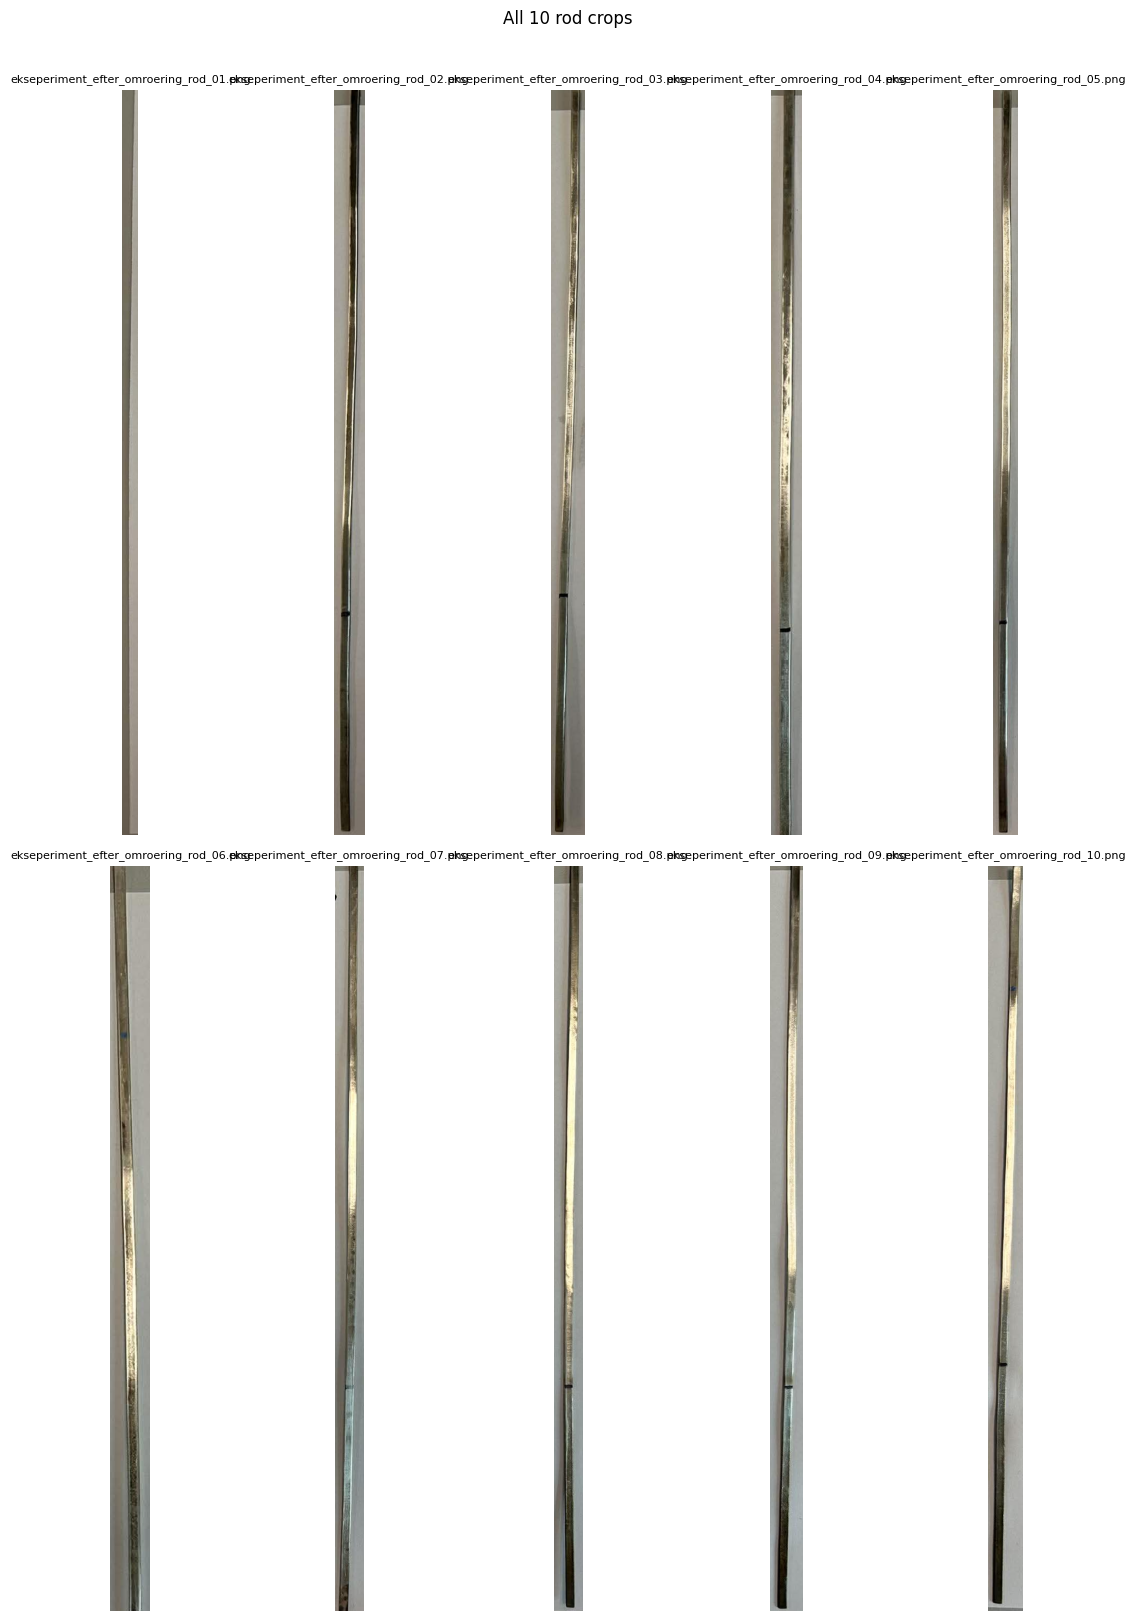

In [234]:
n = len(crops)
if n == 0:
    print("No crops to display.")
else:
    cols_grid = min(n, 5)
    rows_grid = (n + cols_grid - 1) // cols_grid
    fig, axes = plt.subplots(rows_grid, cols_grid,
                             figsize=(cols_grid * 2.5, rows_grid * 8))
    axes = np.array(axes).flatten()

    for ax, crop, path in zip(axes, crops, saved_paths):
        ax.imshow(crop)
        ax.set_title(os.path.basename(path), fontsize=8)
        ax.axis("off")

    for ax in axes[n:]:
        ax.set_visible(False)

    plt.suptitle(f"All {n} rod crops", fontsize=12, y=1.01)
    plt.tight_layout()
    plt.show()